# EduPredict AI — Day 3: Machine Learning Prediction Engine

**Goal:** Train and evaluate separate regression pipelines to predict student final grade (`G3`, `0–20`) for **Mathematics** (`student-mat.csv`) and **Portuguese** (`student-por.csv`) across two realistic prediction scenarios:
- **Scenario A — Early Prediction:** Excludes `G1` and `G2` (uses only demographic, school, and behavioral features available before term exams).
- **Scenario B — Late Prediction:** Includes `G1` and `G2` (mid-year prediction once period grades are known).

**Algorithms Compared:**
1. `LinearRegression`
2. `DecisionTreeRegressor`
3. `RandomForestRegressor`

**Key Engineering Rules Followed:**
- Original datasets in `data/raw/` remain untouched.
- Train/test split (`test_size=0.2`, `random_state=42`) happens **before** any scaling or encoding.
- Preprocessing (`StandardScaler` + `OneHotEncoder`) is wrapped inside a `ColumnTransformer` + `Pipeline` fit strictly on `X_train` to prevent data leakage.
- Best models are selected strictly by **Test** performance (`RMSE`, `MAE`, `R2`), never training performance.

## 1. Setup and Imports

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid", context="notebook")

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
RAW_DIR = PROJECT_ROOT / "data" / "raw"
MODELS_DIR = PROJECT_ROOT / "models"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
FIGURES_DIR = ARTIFACTS_DIR / "figures"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.2
print("Project root:", PROJECT_ROOT)

Project root: <project-root>


## 2. Load Original Datasets (Read-Only)
We load both raw UCI files separately and preserve all rows (including genuine `absences` outliers and `G3 = 0` cases) so evaluation reflects real-world student data.

In [2]:
def load_subject_dataset(filename: str) -> pd.DataFrame:
    """Load a raw UCI student CSV without modifying the original file."""
    return pd.read_csv(RAW_DIR / filename, sep=";")


datasets = {
    "Mathematics": load_subject_dataset("student-mat.csv"),
    "Portuguese": load_subject_dataset("student-por.csv"),
}

for name, df in datasets.items():
    print(f"{name}: shape={df.shape}, missing={int(df.isnull().sum().sum())}, target G3 mean={df['G3'].mean():.2f}")

Mathematics: shape=(395, 33), missing=0, target G3 mean=10.42
Portuguese: shape=(649, 33), missing=0, target G3 mean=11.91


## 3. Modular Pipeline, Leakage Checks & Evaluation Helpers
Each helper function below has one clear responsibility:
1. `prepare_scenario_split`: separates features `X` and target `y = G3` according to the scenario (`early` excludes `G1` & `G2`; `late` includes them), then splits into train/test sets using `random_state=42`.
2. `verify_no_leakage`: programmatically asserts that `G3` is never in `X`, `G1`/`G2` are absent in `early`, and train/test indices have zero overlap.
3. `build_preprocessor`: creates an unfitted `ColumnTransformer` (`StandardScaler` for numeric columns, `OneHotEncoder(handle_unknown="ignore")` for categorical columns).
4. `evaluate_pipeline`: computes both Train and Test `MAE`, `RMSE`, and `R2` so overfitting is immediately visible.

In [3]:
def prepare_scenario_split(df: pd.DataFrame, scenario: str, test_size: float = TEST_SIZE, random_state: int = RANDOM_STATE):
    """Split dataframe into train/test sets for 'early' (no G1/G2) or 'late' (with G1/G2) prediction."""
    if scenario == "early":
        drop_cols = ["G1", "G2", "G3"]
    elif scenario == "late":
        drop_cols = ["G3"]
    else:
        raise ValueError(f"Unknown scenario: {scenario}")

    X = df.drop(columns=drop_cols).copy()
    y = df["G3"].copy()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    return X_train, X_test, y_train, y_test


def verify_no_leakage(X_train: pd.DataFrame, X_test: pd.DataFrame, y_train: pd.Series, y_test: pd.Series, scenario: str) -> None:
    """Verify there is no target or train/test index leakage."""
    assert "G3" not in X_train.columns and "G3" not in X_test.columns, "Target G3 leaked into features!"
    if scenario == "early":
        for grade_col in ["G1", "G2"]:
            assert grade_col not in X_train.columns and grade_col not in X_test.columns, (
                f"{grade_col} leaked into early prediction features!"
            )
    assert set(X_train.index).isdisjoint(set(X_test.index)), "Train and test sets share overlapping indices!"
    assert len(X_train) == len(y_train) and len(X_test) == len(y_test), "X and y lengths do not match!"


def build_preprocessor(X_train: pd.DataFrame) -> ColumnTransformer:
    """Create an unfitted ColumnTransformer for numeric scaling and categorical one-hot encoding."""
    numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
    categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ]
    )


def get_candidate_models() -> dict:
    """Return fresh instances of the three regression algorithms."""
    return {
        "Linear Regression": LinearRegression(),
        "Decision Tree Regressor": DecisionTreeRegressor(random_state=RANDOM_STATE),
        "Random Forest Regressor": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    }


def evaluate_pipeline(pipeline: Pipeline, X_train, X_test, y_train, y_test) -> dict:
    """Compute MAE, RMSE, and R2 on both train and unseen test splits."""
    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    return {
        "Train_MAE": float(mean_absolute_error(y_train, train_pred)),
        "Train_RMSE": float(root_mean_squared_error(y_train, train_pred)),
        "Train_R2": float(r2_score(y_train, train_pred)),
        "Test_MAE": float(mean_absolute_error(y_test, test_pred)),
        "Test_RMSE": float(root_mean_squared_error(y_test, test_pred)),
        "Test_R2": float(r2_score(y_test, test_pred)),
        "test_pred": test_pred,
    }

## 4. Train, Check Leakage, and Evaluate All Models
We train all 3 algorithms across all 4 tasks (`Mathematics Early`, `Mathematics Late`, `Portuguese Early`, `Portuguese Late`) and select the best model for each task strictly based on **lowest `Test_RMSE`**.

In [4]:
all_records = []
trained_pipelines = {}   # (subject, scenario, model_name) -> fitted Pipeline
splits_store = {}        # (subject, scenario) -> (X_train, X_test, y_train, y_test)
predictions_store = {}   # (subject, scenario, model_name) -> y_test_pred

scenarios = {
    "early": "Scenario A (Early: No G1/G2)",
    "late": "Scenario B (Late: With G1/G2)",
}

for subject_name, df in datasets.items():
    for scenario_key, scenario_label in scenarios.items():
        X_train, X_test, y_train, y_test = prepare_scenario_split(df, scenario_key)
        verify_no_leakage(X_train, X_test, y_train, y_test, scenario_key)
        splits_store[(subject_name, scenario_key)] = (X_train, X_test, y_train, y_test)

        print(
            f"[Leakage Check PASSED] {subject_name} | {scenario_label} | "
            f"features={X_train.shape[1]} | train={len(X_train)} | test={len(X_test)}"
        )

        for model_name, estimator in get_candidate_models().items():
            preprocessor = build_preprocessor(X_train)
            pipe = Pipeline(steps=[
                ("preprocessor", preprocessor),
                ("model", estimator),
            ])
            pipe.fit(X_train, y_train)

            metrics = evaluate_pipeline(pipe, X_train, X_test, y_train, y_test)
            test_pred = metrics.pop("test_pred")

            trained_pipelines[(subject_name, scenario_key, model_name)] = pipe
            predictions_store[(subject_name, scenario_key, model_name)] = test_pred

            all_records.append({
                "Subject": subject_name,
                "Scenario": scenario_key,
                "Scenario_Label": scenario_label,
                "Model": model_name,
                "Num_Features": X_train.shape[1],
                **metrics,
            })

results_df = pd.DataFrame(all_records)
display_cols = [
    "Subject", "Scenario", "Model", "Num_Features",
    "Train_MAE", "Train_RMSE", "Train_R2",
    "Test_MAE", "Test_RMSE", "Test_R2"
]
print("\n=== Complete Model Comparison Table (Sorted by Subject, Scenario, Test_RMSE) ===")
display(results_df[display_cols].sort_values(["Subject", "Scenario", "Test_RMSE"]).round(4))

[Leakage Check PASSED] Mathematics | Scenario A (Early: No G1/G2) | features=30 | train=316 | test=79


[Leakage Check PASSED] Mathematics | Scenario B (Late: With G1/G2) | features=32 | train=316 | test=79


[Leakage Check PASSED] Portuguese | Scenario A (Early: No G1/G2) | features=30 | train=519 | test=130


[Leakage Check PASSED] Portuguese | Scenario B (Late: With G1/G2) | features=32 | train=519 | test=130



=== Complete Model Comparison Table (Sorted by Subject, Scenario, Test_RMSE) ===


,Subject,Scenario,Model,Num_Features,Train_MAE,Train_RMSE,Train_R2,Test_MAE,Test_RMSE,Test_R2
2,Mathematics,early,Random Forest Regressor,30,1.0875,1.4560,0.8991,2.9938,3.7508,0.3139
0,Mathematics,early,Linear Regression,30,2.9462,3.8651,0.2888,3.3953,4.1957,0.1415
1,Mathematics,early,Decision Tree Regressor,30,0.0000,0.0000,1.0000,3.6329,4.8379,-0.1414
5,Mathematics,late,Random Forest Regressor,32,0.3363,0.5687,0.9846,1.2005,2.0150,0.8020
3,Mathematics,late,Linear Regression,32,1.1645,1.6802,0.8656,1.6467,2.3784,0.7241
4,Mathematics,late,Decision Tree Regressor,32,0.0000,0.0000,1.0000,1.3165,2.5705,0.6778
8,Portuguese,early,Random Forest Regressor,30,0.7382,1.0138,0.9024,2.0452,2.8166,0.1865
6,Portuguese,early,Linear Regression,30,1.8320,2.5392,0.3874,2.1564,2.8618,0.1602
7,Portuguese,early,Decision Tree Regressor,30,0.0000,0.0000,1.0000,2.8615,3.7988,-0.4798
9,Portuguese,late,Linear Regression,32,0.7952,1.2211,0.8583,0.7651,1.2149,0.8487


In [5]:
# Select the best model per (Subject, Scenario) strictly using Test_RMSE (lowest test error)
best_idx = results_df.groupby(["Subject", "Scenario"])["Test_RMSE"].idxmin()
best_models_df = results_df.loc[best_idx].sort_values(["Subject", "Scenario"]).reset_index(drop=True)

print("=== Best Selected Models (Based Strictly on Unseen Test Performance) ===")
display(best_models_df[display_cols].round(4))

=== Best Selected Models (Based Strictly on Unseen Test Performance) ===


,Subject,Scenario,Model,Num_Features,Train_MAE,Train_RMSE,Train_R2,Test_MAE,Test_RMSE,Test_R2
0,Mathematics,early,Random Forest Regressor,30,1.0875,1.4560,0.8991,2.9938,3.7508,0.3139
1,Mathematics,late,Random Forest Regressor,32,0.3363,0.5687,0.9846,1.2005,2.0150,0.8020
2,Portuguese,early,Random Forest Regressor,30,0.7382,1.0138,0.9024,2.0452,2.8166,0.1865
3,Portuguese,late,Linear Regression,32,0.7952,1.2211,0.8583,0.7651,1.2149,0.8487


## 5. Model Comparison Visualizations
We generate three sets of plots in `artifacts/figures/`:
1. **Test Metrics Comparison** (`09_ml_model_comparison_metrics.png`): Compares Test MAE, Test RMSE, and Test $R^2$ across all 3 models in both Early and Late scenarios.
2. **Actual vs Predicted `G3`** (`10_ml_actual_vs_predicted.png`): Shows how closely each best selected model predicts unseen test students.
3. **Train vs Test $R^2$ Overfitting Check** (`11_ml_train_vs_test_overfitting.png`): Demonstrates why training scores cannot be used to choose models (e.g., an unpruned Decision Tree memorizes training data with $R^2 = 1.00$).

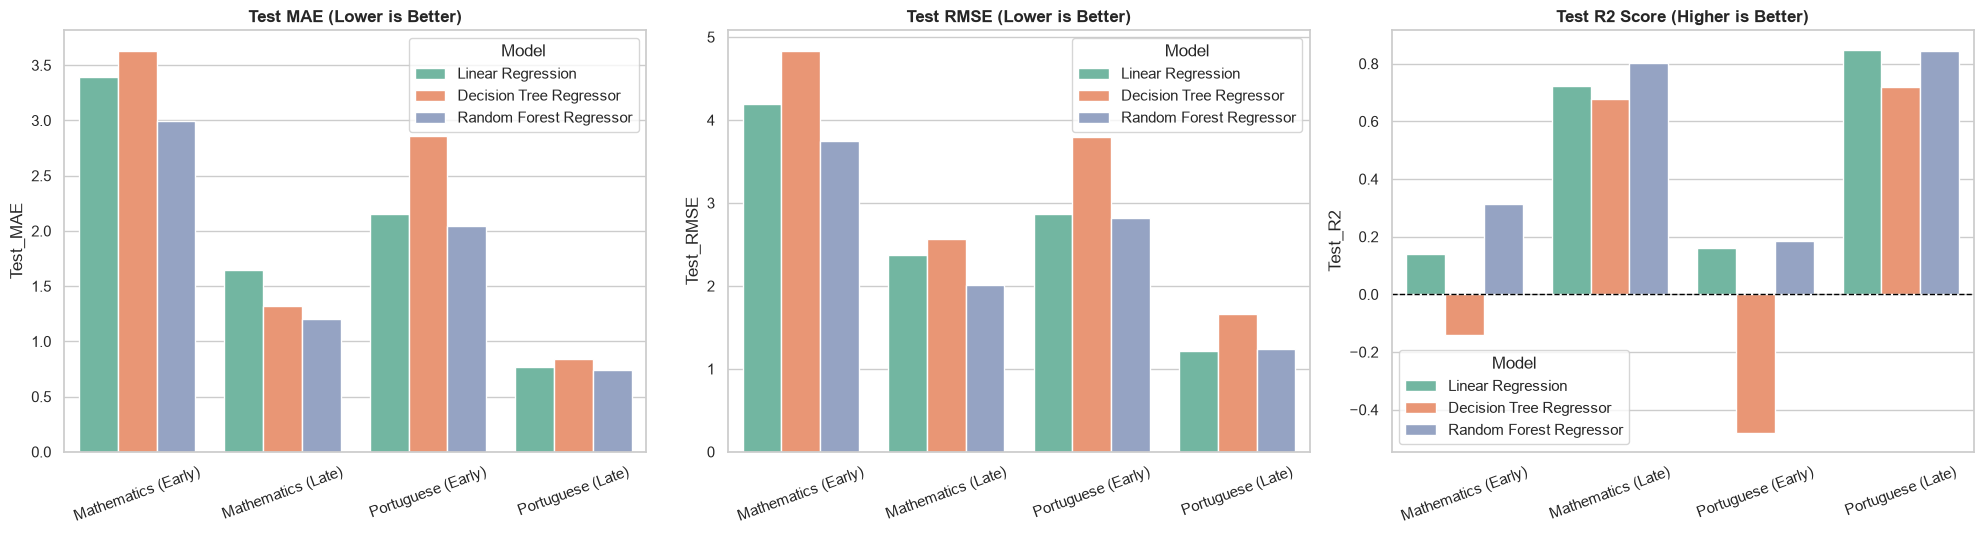

Saved: 09_ml_model_comparison_metrics.png


In [6]:
results_df["Task"] = results_df["Subject"] + " (" + results_df["Scenario"].str.title() + ")"
task_order = [
    "Mathematics (Early)",
    "Mathematics (Late)",
    "Portuguese (Early)",
    "Portuguese (Late)",
]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
metric_specs = [
    ("Test_MAE", "Test MAE (Lower is Better)"),
    ("Test_RMSE", "Test RMSE (Lower is Better)"),
    ("Test_R2", "Test R2 Score (Higher is Better)"),
]

for ax, (metric_col, title) in zip(axes, metric_specs):
    sns.barplot(data=results_df, x="Task", y=metric_col, hue="Model",
                order=task_order, palette="Set2", ax=ax)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(metric_col)
    ax.tick_params(axis="x", rotation=20)
    if metric_col == "Test_R2":
        ax.axhline(0, color="black", linestyle="--", linewidth=1)

plt.tight_layout()
fig9_path = FIGURES_DIR / "09_ml_model_comparison_metrics.png"
plt.savefig(fig9_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", fig9_path.name)

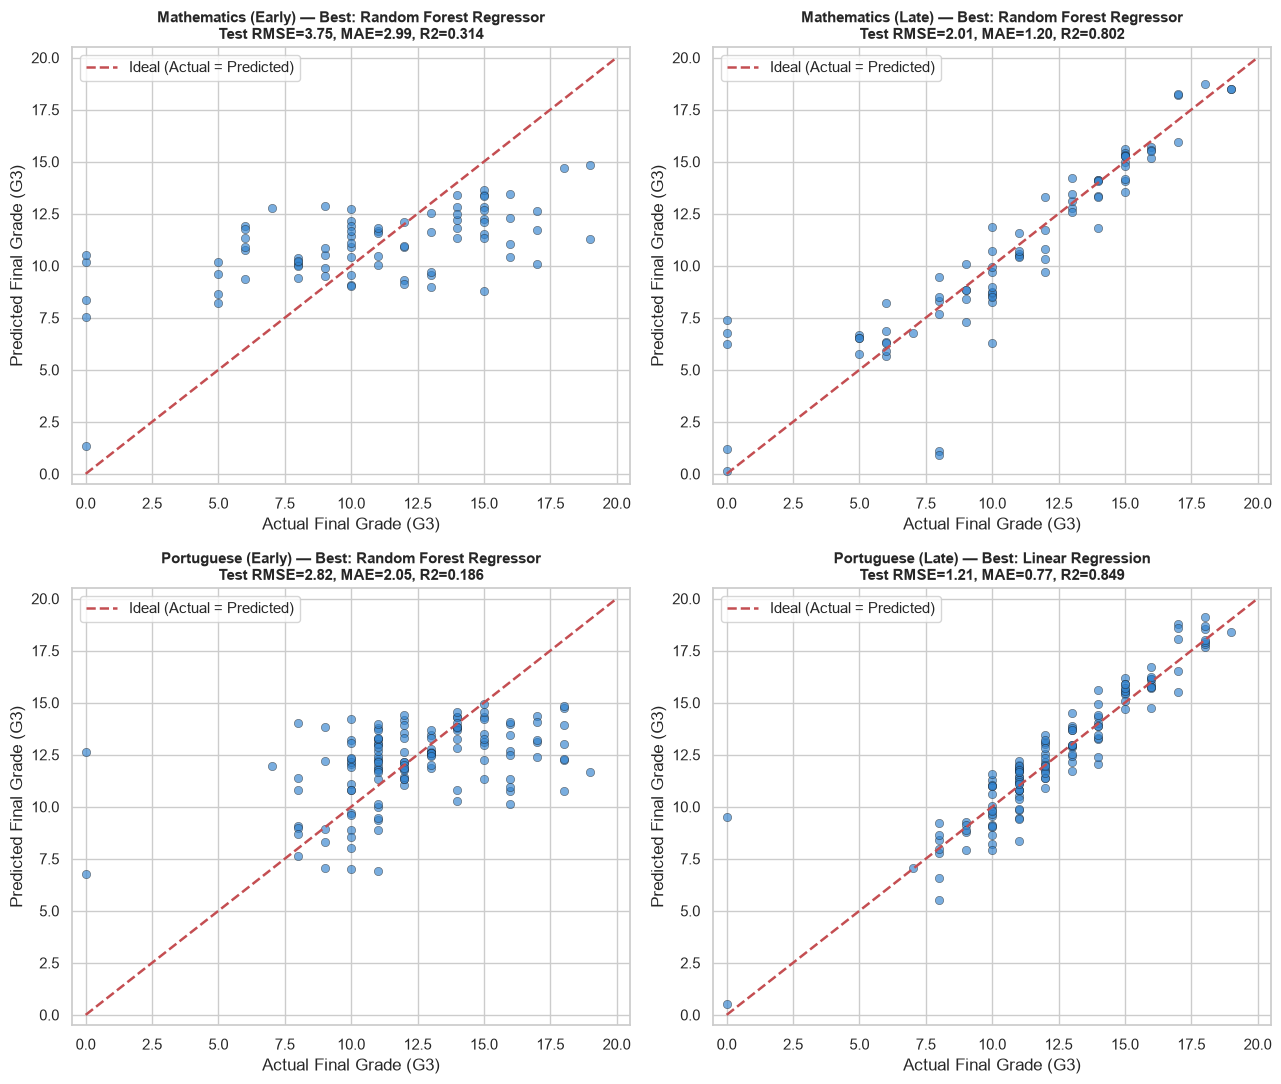

Saved: 10_ml_actual_vs_predicted.png


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()

for ax, (_, row) in zip(axes, best_models_df.iterrows()):
    subj = row["Subject"]
    scen = row["Scenario"]
    best_model_name = row["Model"]
    _, X_test, _, y_test = splits_store[(subj, scen)]
    y_pred = predictions_store[(subj, scen, best_model_name)]

    ax.scatter(y_test, y_pred, alpha=0.65, edgecolors="k", linewidth=0.4, color="#3182ce")
    ax.plot([0, 20], [0, 20], "r--", linewidth=1.8, label="Ideal (Actual = Predicted)")
    ax.set_title(
        f"{subj} ({scen.title()}) — Best: {best_model_name}\n"
        f"Test RMSE={row['Test_RMSE']:.2f}, MAE={row['Test_MAE']:.2f}, R2={row['Test_R2']:.3f}",
        fontsize=11, fontweight="bold"
    )
    ax.set_xlabel("Actual Final Grade (G3)")
    ax.set_ylabel("Predicted Final Grade (G3)")
    ax.set_xlim(-0.5, 20.5)
    ax.set_ylim(-0.5, 20.5)
    ax.legend()

plt.tight_layout()
fig10_path = FIGURES_DIR / "10_ml_actual_vs_predicted.png"
plt.savefig(fig10_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", fig10_path.name)

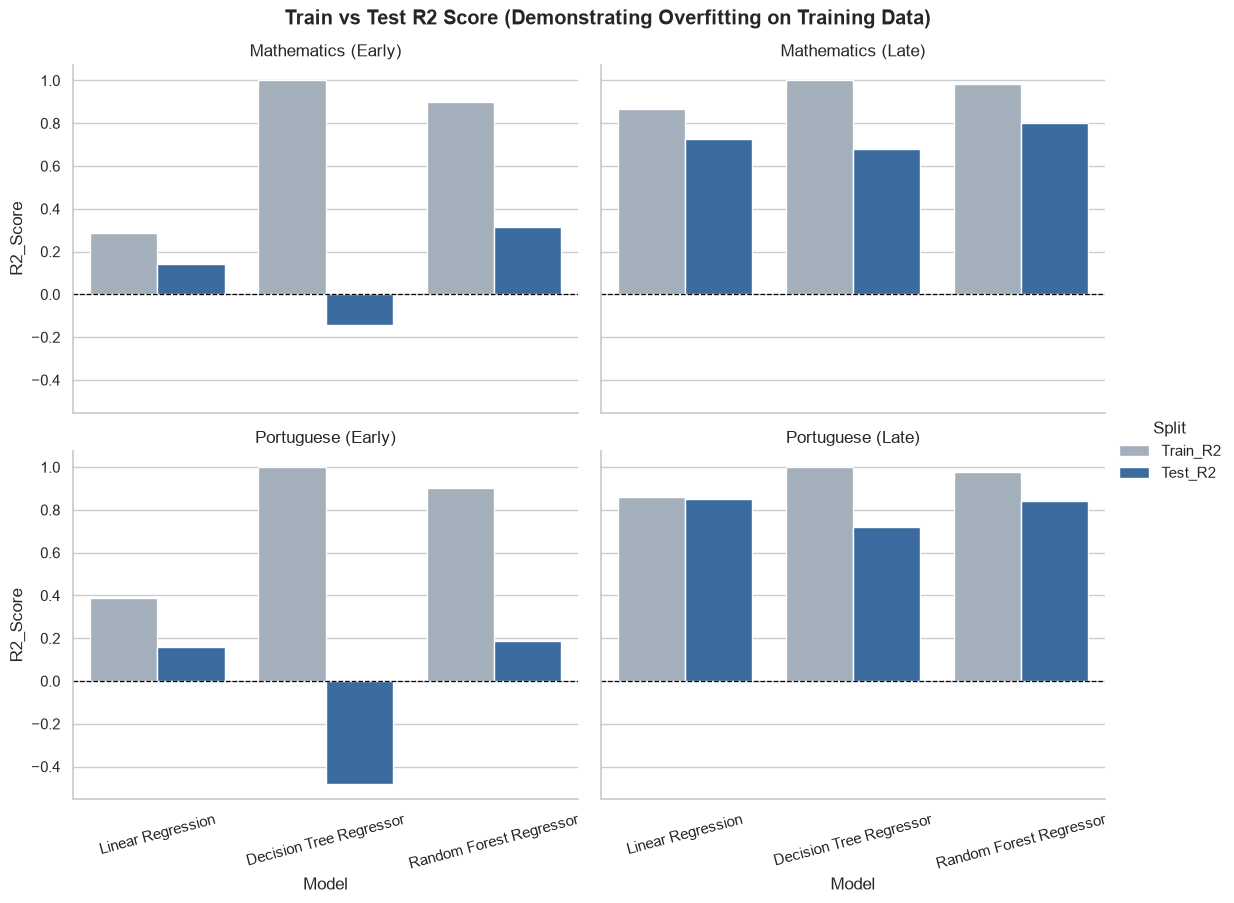

Saved: 11_ml_train_vs_test_overfitting.png


In [8]:
overfit_melt = results_df.melt(
    id_vars=["Task", "Model"],
    value_vars=["Train_R2", "Test_R2"],
    var_name="Split",
    value_name="R2_Score"
)

g = sns.catplot(
    data=overfit_melt, x="Model", y="R2_Score", hue="Split", col="Task",
    col_wrap=2, kind="bar", height=4.2, aspect=1.35, palette=["#a0aec0", "#2b6cb0"]
)
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.axhline(0, color="black", linestyle="--", linewidth=0.9)
    ax.tick_params(axis="x", rotation=15)
g.fig.suptitle("Train vs Test R2 Score (Demonstrating Overfitting on Training Data)", y=1.02, fontweight="bold")

fig11_path = FIGURES_DIR / "11_ml_train_vs_test_overfitting.png"
plt.savefig(fig11_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", fig11_path.name)

## 6. Save Best Pipelines (`models/`) and Evaluation Artifacts (`artifacts/`)
Each saved `.joblib` file contains **both** the fitted `ColumnTransformer` preprocessor and the winning regression estimator inside one `Pipeline`, ready to accept raw student feature dictionaries/DataFrames.

In [9]:
saved_summary = []

for _, row in best_models_df.iterrows():
    subj = row["Subject"]
    scen = row["Scenario"]
    model_name = row["Model"]
    pipe = trained_pipelines[(subj, scen, model_name)]
    X_train, _, _, _ = splits_store[(subj, scen)]

    short_subj = "math" if subj == "Mathematics" else "portuguese"
    model_filename = f"{short_subj}_{scen}_pipeline.joblib"
    model_path = MODELS_DIR / model_filename
    joblib.dump(pipe, model_path)

    saved_summary.append({
        "subject": subj,
        "scenario": scen,
        "selected_model": model_name,
        "pipeline_file": str(model_path.relative_to(PROJECT_ROOT)),
        "feature_columns": list(X_train.columns),
        "test_mae": round(float(row["Test_MAE"]), 4),
        "test_rmse": round(float(row["Test_RMSE"]), 4),
        "test_r2": round(float(row["Test_R2"]), 4),
    })
    print(f"Saved pipeline: {model_path.name} ({model_name})")

# Save evaluation results CSV and JSON inside artifacts/ and model metadata inside models/
eval_csv_path = ARTIFACTS_DIR / "ml_evaluation_results.csv"
results_df.drop(columns=["Task"]).round(4).to_csv(eval_csv_path, index=False)

summary_json_path = ARTIFACTS_DIR / "ml_best_models_summary.json"
summary_json_path.write_text(json.dumps(saved_summary, indent=2))

metadata_json_path = MODELS_DIR / "ml_model_metadata.json"
metadata_json_path.write_text(json.dumps(saved_summary, indent=2))

print(f"Saved evaluation table : {eval_csv_path.relative_to(PROJECT_ROOT)}")
print(f"Saved best-model summary: {summary_json_path.relative_to(PROJECT_ROOT)}")
print(f"Saved model metadata   : {metadata_json_path.relative_to(PROJECT_ROOT)}")

Saved pipeline: math_early_pipeline.joblib (Random Forest Regressor)
Saved pipeline: math_late_pipeline.joblib (Random Forest Regressor)
Saved pipeline: portuguese_early_pipeline.joblib (Random Forest Regressor)
Saved pipeline: portuguese_late_pipeline.joblib (Linear Regression)
Saved evaluation table : artifacts/ml_evaluation_results.csv
Saved best-model summary: artifacts/ml_best_models_summary.json
Saved model metadata   : models/ml_model_metadata.json


## 7. Verify Predictions on Unseen Test Samples
We reload each saved `.joblib` pipeline from disk and predict `G3` on 5 unseen test students (`X_test.iloc[:5]`) to prove the saved preprocessing + model pipelines work end-to-end on raw input rows.

In [10]:
for item in saved_summary:
    subj = item["subject"]
    scen = item["scenario"]
    loaded_pipe = joblib.load(PROJECT_ROOT / item["pipeline_file"])
    _, X_test, _, y_test = splits_store[(subj, scen)]

    sample_X = X_test.iloc[:5]
    sample_y = y_test.iloc[:5]
    sample_preds = loaded_pipe.predict(sample_X)

    preview = pd.DataFrame({
        "Actual_G3": sample_y.values,
        "Predicted_G3": np.round(sample_preds, 2),
        "Abs_Error": np.round(np.abs(sample_y.values - sample_preds), 2),
    }, index=sample_X.index)

    print(f"\n=== Unseen Test Verification: {subj} ({scen}) | {item['selected_model']} ===")
    display(preview)


=== Unseen Test Verification: Mathematics (early) | Random Forest Regressor ===


,Actual_G3,Predicted_G3,Abs_Error
78,10,9.57,0.43
371,12,9.32,2.69
248,5,10.20,5.20
55,10,12.14,2.13
390,9,9.90,0.89



=== Unseen Test Verification: Mathematics (late) | Random Forest Regressor ===


,Actual_G3,Predicted_G3,Abs_Error
78,10,8.25,1.75
371,12,11.73,0.27
248,5,6.66,1.66
55,10,9.70,0.30
390,9,8.82,0.19



=== Unseen Test Verification: Portuguese (early) | Random Forest Regressor ===


,Actual_G3,Predicted_G3,Abs_Error
636,19,11.66,7.35
220,12,12.62,0.62
594,18,13.03,4.97
429,11,11.82,0.82
72,11,11.98,0.97



=== Unseen Test Verification: Portuguese (late) | Linear Regression ===


,Actual_G3,Predicted_G3,Abs_Error
636,19,18.40,0.60
220,12,11.83,0.17
594,18,18.56,0.56
429,11,10.81,0.19
72,11,11.74,0.74


## 8. Model Limitations & Engineering Notes
1. **Small sample sizes:** Mathematics has only `395` rows (`79` test samples) and Portuguese has `649` rows (`130` test samples). Metrics on a single 20% test split can fluctuate if the split changes.
2. **Early prediction difficulty (`Scenario A`):** Without `G1` and `G2`, behavioral and demographic survey features alone only explain a modest portion of `G3` variance (low $R^2$ and larger MAE/RMSE), because prior academic performance and unmeasured factors (study quality, exam day readiness, teacher effects) strongly influence final grades.
3. **Late prediction dependence on `G1` & `G2` (`Scenario B`):** High accuracy in Scenario B depends heavily on `G1` and `G2` already being available, which means Scenario B cannot be used at the start of a semester.
4. **`G3 = 0` dropout/non-attendance spike:** As seen in Day 2, `38` Math students and `15` Portuguese students have `G3 = 0` (even with passing `G1`/`G2` and `absences = 0`). Regression models struggle to anticipate unexpected zero grades, inflating RMSE.
5. **Overfitting in unpruned Decision Trees:** `DecisionTreeRegressor` achieves near-`1.00` training $R^2$ by memorizing training rows, yet performs worst on unseen test rows — proving why test-set evaluation is mandatory.
6. **Unbounded linear predictions:** `LinearRegression` can occasionally output values slightly below `0` or above `20` on extreme inputs; downstream applications can clip display predictions to `[0, 20]` if needed.